In [33]:
#from google.colab import files

#uploaded = files.upload()

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)
from sklearn.inspection import permutation_importance

# Load the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (23967, 75)


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,G,...,n_obs_used,n_del_obs_used,n_dop_obs_used,condition_code,rms,two_body,A1,A2,A3,DT
0,a0000433,2000433,433 Eros (A898 PA),433,Eros,NaN,Y,N,10.4,0.46,...,8767,4.0,2.0,0.0,0.28397,NaN,NaN,NaN,NaN,NaN
1,a0000719,2000719,719 Albert (A911 TB),719,Albert,NaN,Y,N,15.5,NaN,...,1874,NaN,NaN,0.0,0.39148,NaN,NaN,NaN,NaN,NaN
2,a0000887,2000887,887 Alinda (A918 AA),887,Alinda,NaN,Y,N,13.8,-0.12,...,1424,NaN,NaN,0.0,0.48159,NaN,NaN,NaN,NaN,NaN
3,a0001036,2001036,1036 Ganymed (A924 UB),1036,Ganymed,NaN,Y,N,9.4,0.30,...,6249,0.0,1.0,0.0,0.38525,NaN,NaN,NaN,NaN,NaN
4,a0001221,2001221,1221 Amor (1932 EA1),1221,Amor,NaN,Y,N,17.7,NaN,...,540,NaN,NaN,0.0,0.45568,NaN,NaN,NaN,NaN,NaN


In [35]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows: 23967
Number of columns: 75

Column names:
['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H', 'G', 'M1', 'M2', 'K1', 'K2', 'PC', 'diameter', 'extent', 'albedo', 'rot_per', 'GM', 'BV', 'UB', 'IR', 'spec_B', 'spec_T', 'H_sigma', 'diameter_sigma', 'orbit_id', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'moid_jup', 't_jup', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class', 'producer', 'data_arc', 'first_obs', 'last_obs', 'n_obs_used', 'n_del_obs_used', 'n_dop_obs_used', 'condition_code', 'rms', 'two_body', 'A1', 'A2', 'A3', 'DT']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23967 entries, 0 to 23966
Data columns (total 75 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,G,...,n_obs_used,n_del_obs_used,n_dop_obs_used,condition_code,rms,two_body,A1,A2,A3,DT
0,a0000433,2000433,433 Eros (A898 PA),433,Eros,NaN,Y,N,10.4,0.46,...,8767,4.0,2.0,0.0,0.28397,NaN,NaN,NaN,NaN,NaN
1,a0000719,2000719,719 Albert (A911 TB),719,Albert,NaN,Y,N,15.5,NaN,...,1874,NaN,NaN,0.0,0.39148,NaN,NaN,NaN,NaN,NaN
2,a0000887,2000887,887 Alinda (A918 AA),887,Alinda,NaN,Y,N,13.8,-0.12,...,1424,NaN,NaN,0.0,0.48159,NaN,NaN,NaN,NaN,NaN
3,a0001036,2001036,1036 Ganymed (A924 UB),1036,Ganymed,NaN,Y,N,9.4,0.30,...,6249,0.0,1.0,0.0,0.38525,NaN,NaN,NaN,NaN,NaN
4,a0001221,2001221,1221 Amor (1932 EA1),1221,Amor,NaN,Y,N,17.7,NaN,...,540,NaN,NaN,0.0,0.45568,NaN,NaN,NaN,NaN,NaN



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,23967,23967,dK20P04c,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spkid,23967.0,NaN,NaN,NaN,6759972.754746,12514344.103622,1000004.0,3402130.5,3698557.0,3799853.5,54054685.0
full_name,23967,23967,C/2020 P4-C,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pdes,23967,23967,2020 P4-C,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,343,240,Schwassmann-Wachmann,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
two_body,15,2,F,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A1,54.0,NaN,NaN,NaN,0.0,0.0,-0.0,0.0,0.0,0.0,0.000001
A2,177.0,NaN,NaN,NaN,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0
A3,15.0,NaN,NaN,NaN,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0


In [36]:
# Make a working copy
data = df.copy()

# Normalize target labels
data["pha"] = (
    data["pha"].astype("string").str.strip().str.upper()
)

# Convert the target to binary form: Y = 1, N = 0
data["target"] = data["pha"].map({"Y": 1, "N": 0})

# Convert important numerical columns to numeric safely
numeric_columns = [
    "H", "moid", "e", "a", "q", "i", "om", "w",
    "ad", "n", "per_y", "H_sigma", "sigma_e",
    "sigma_a", "sigma_q", "sigma_i", "sigma_om",
    "sigma_w", "data_arc", "n_obs_used",
    "condition_code", "rms"
]

for col in numeric_columns:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Duplicate audit
print("Duplicate rows:", data.duplicated().sum())

if "spkid" in data.columns:
    print("Duplicate asteroid IDs:", data["spkid"].duplicated().sum())

# Remove duplicate records, if any
data = data.drop_duplicates()

# Keep rows with known target labels
labelled = data.dropna(subset=["target"]).copy()
labelled["target"] = labelled["target"].astype(int)

print("\nRows before removing missing labels:", len(data))
print("Rows with valid PHA labels:", len(labelled))
print("Rows with missing PHA labels:", data["target"].isna().sum())

print("\nTarget distribution:")
display(labelled["target"].value_counts().rename(index={0: "N", 1: "Y"}))

print("\nTarget percentages:")
display(
    (labelled["target"].value_counts(normalize=True) * 100)
    .rename(index={0: "N", 1: "Y"})
    .round(2)
)

Duplicate rows: 0
Duplicate asteroid IDs: 0

Rows before removing missing labels: 23967
Rows with valid PHA labels: 23779
Rows with missing PHA labels: 188

Target distribution:


,count
target,
N,21674
Y,2105



Target percentages:


,proportion
target,
N,91.15
Y,8.85


,Missing_Count,Missing_Percentage,Data_Type
M2,23779,100.00,float64
M1,23779,100.00,float64
K2,23779,100.00,float64
K1,23779,100.00,float64
DT,23779,100.00,float64
PC,23779,100.00,float64
A3,23779,100.00,float64
two_body,23779,100.00,object
prefix,23778,100.00,object
IR,23778,100.00,float64


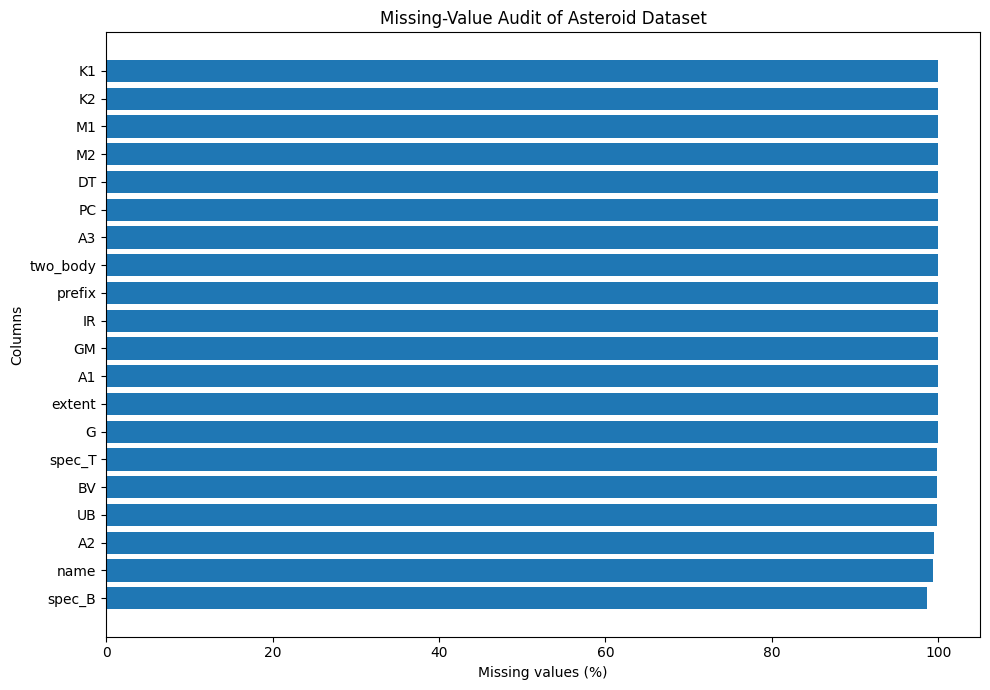

In [37]:
missing_audit = pd.DataFrame({
    "Missing_Count": labelled.isnull().sum(),
    "Missing_Percentage": labelled.isnull().mean() * 100,
    "Data_Type": labelled.dtypes.astype(str)
})

missing_audit = missing_audit.sort_values(
    "Missing_Percentage", ascending=False
)

display(missing_audit.head(25).round(2))

# Visualize the 20 columns with the highest missing percentages
top_missing = missing_audit.head(20).sort_values(
    "Missing_Percentage"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_missing.index,
    top_missing["Missing_Percentage"]
)
plt.xlabel("Missing values (%)")
plt.ylabel("Columns")
plt.title("Missing-Value Audit of Asteroid Dataset")
plt.tight_layout()
plt.show()

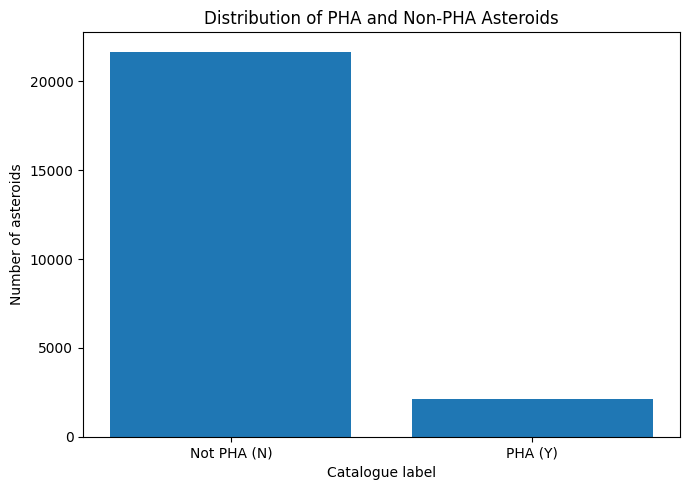

PHA prevalence: 8.85%
Non-PHA prevalence: 91.15%
Majority-class baseline accuracy: 0.9115
Important: majority-class accuracy does not measure PHA detection.


In [38]:
target_counts = labelled["target"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Not PHA (N)", "PHA (Y)"],
    [target_counts.get(0, 0), target_counts.get(1, 0)]
)
plt.title("Distribution of PHA and Non-PHA Asteroids")
plt.ylabel("Number of asteroids")
plt.xlabel("Catalogue label")
plt.tight_layout()
plt.show()

positive_rate = labelled["target"].mean()

print(f"PHA prevalence: {positive_rate:.2%}")
print(f"Non-PHA prevalence: {1-positive_rate:.2%}")
print(
    "Majority-class baseline accuracy:",
    round(max(positive_rate, 1-positive_rate), 4)
)
print("Important: majority-class accuracy does not measure PHA detection.")

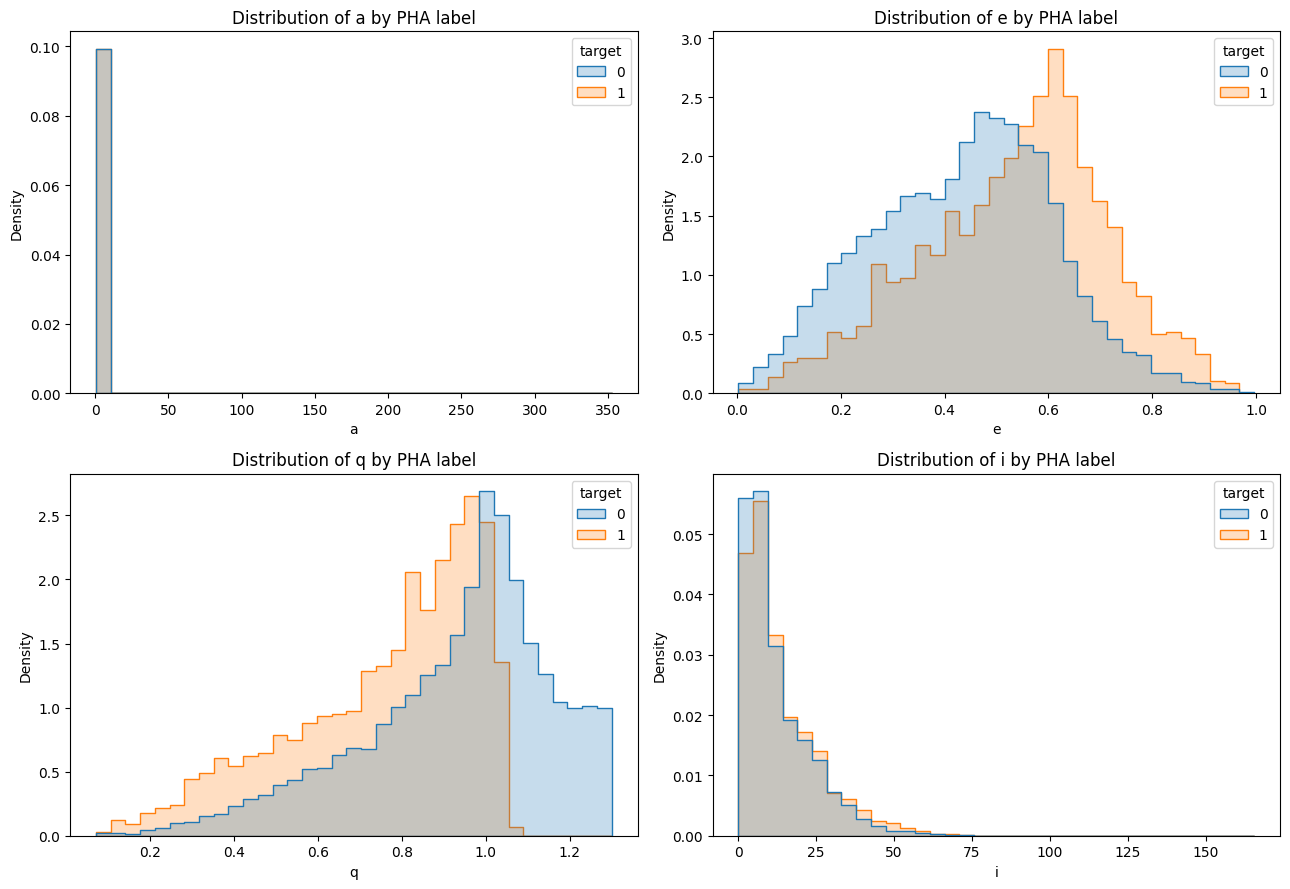

In [39]:
# Orbital feature distributions by PHA label
plot_columns = ["a", "e", "q", "i"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, col in zip(axes, plot_columns):
    sns.histplot(
        data=labelled,
        x=col,
        hue="target",
        bins=35,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )
    ax.set_title(f"Distribution of {col} by PHA label")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()



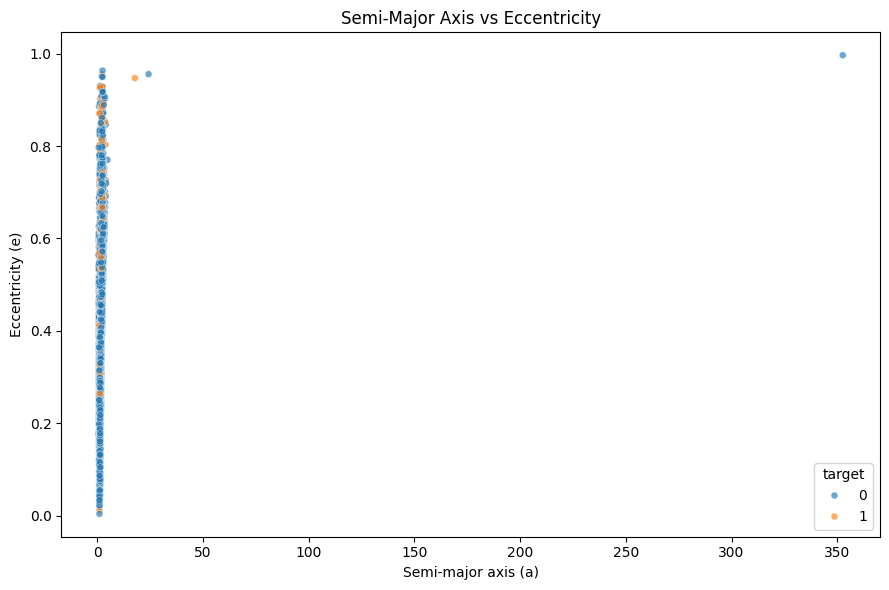

In [40]:
# Orbital scatterplot
sample_data = labelled.sample(
    min(5000, len(labelled)), random_state=42
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_data,
    x="a",
    y="e",
    hue="target",
    alpha=0.65,
    s=25
)
plt.title("Semi-Major Axis vs Eccentricity")
plt.xlabel("Semi-major axis (a)")
plt.ylabel("Eccentricity (e)")
plt.tight_layout()
plt.show()

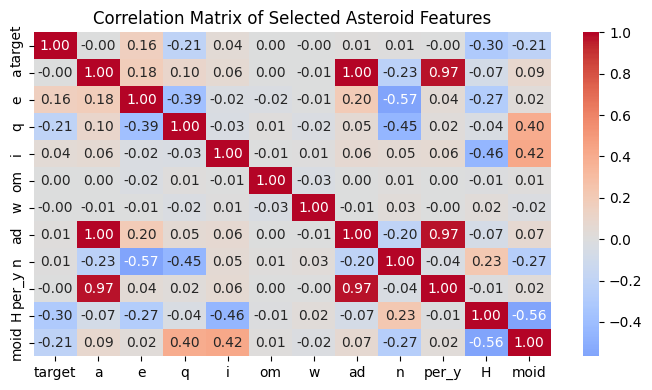

Correlation of selected variables with target:


,target
target,1.000000
e,0.160036
i,0.040837
ad,0.009517
n,0.008163
om,0.000484
a,-0.000642
per_y,-0.001852
w,-0.003618
q,-0.207608


In [41]:
corr_columns = [
    c for c in [
        "target", "a", "e", "q", "i", "om", "w",
        "ad", "n", "per_y", "H", "moid"
    ]
    if c in labelled.columns
]

corr_data = labelled[corr_columns].corr(numeric_only=True)

plt.figure(figsize=(7, 4))
sns.heatmap(
    corr_data,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Matrix of Selected Asteroid Features")
plt.tight_layout()
plt.show()

print("Correlation of selected variables with target:")
display(corr_data["target"].sort_values(ascending=False).to_frame())

In [42]:
# Convert orbital angles to circular features
for col in ["om", "w"]:
    if col in labelled.columns:
        radians = np.deg2rad(labelled[col] % 360)
        labelled[f"{col}_sin"] = np.sin(radians)
        labelled[f"{col}_cos"] = np.cos(radians)

# Diagnostic only: compare catalogue labels with a conventional rule
rule_columns_exist = {"moid", "H"}.issubset(labelled.columns)

if rule_columns_exist:
    rule_data = labelled.dropna(subset=["moid", "H"]).copy()

    # Common conventional criteria: MOID <= 0.05 AU and H <= 22
    rule_data["rule_prediction"] = (
        (rule_data["moid"] <= 0.05) &
        (rule_data["H"] <= 22)
    ).astype(int)

    print("Rule diagnostic rows:", len(rule_data))
    print(
        "Rule agreement with catalogue label:",
        round(
            (rule_data["rule_prediction"] == rule_data["target"]).mean(),
            4
        )
    )

    print("\nRule vs catalogue-label confusion matrix:")
    print(
        confusion_matrix(
            rule_data["target"],
            rule_data["rule_prediction"],
            labels=[0, 1]
        )
    )

    print(
        "\nThis is a rule diagnostic, not a machine-learning test result."
    )
else:
    print("MOID/H rule audit skipped: required columns are unavailable.")

Rule diagnostic rows: 23770
Rule agreement with catalogue label: 0.9977

Rule vs catalogue-label confusion matrix:
[[21629    36]
 [   18  2087]]

This is a rule diagnostic, not a machine-learning test result.


In [43]:
# Main orbital features: exclude H, MOID, IDs, names and direct label proxies
features_A = [
    "a", "e", "q", "i", "om", "w", "ad", "n", "per_y"
]

# Engineered features: replace raw angles with circular encoding
features_D = [
    "a", "e", "q", "i",
    "om_sin", "om_cos", "w_sin", "w_cos",
    "ad", "n", "per_y"
]

# Observation-quality variables for a separate proxy audit
quality_candidates = [
    "H_sigma", "sigma_e", "sigma_a", "sigma_q",
    "sigma_i", "sigma_om", "sigma_w",
    "data_arc", "n_obs_used", "condition_code", "rms"
]

features_B = features_D + [
    c for c in quality_candidates
    if c in labelled.columns
]

# Intentionally leaky feature set for demonstration only
features_C = features_D + [
    c for c in ["moid", "H"]
    if c in labelled.columns
]

# Keep only features that exist in the dataset
features_A = [c for c in features_A if c in labelled.columns]
features_D = [c for c in features_D if c in labelled.columns]
features_B = [c for c in features_B if c in labelled.columns]
features_C = [c for c in features_C if c in labelled.columns]

X_all = labelled.copy()
y = labelled["target"].astype(int)

# Stratified split preserves approximately the same class ratio
train_idx, test_idx = train_test_split(
    labelled.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print("Training rows:", len(train_idx))
print("Test rows:", len(test_idx))
print("Training PHA prevalence:", round(y_train.mean(), 4))
print("Test PHA prevalence:", round(y_test.mean(), 4))

print("\nFeature set sizes:")
print("A — Raw orbital:", len(features_A))
print("D — Circular encoding:", len(features_D))
print("B — Observation-quality audit:", len(features_B))
print("C — Direct leakage diagnostic:", len(features_C))

Training rows: 19023
Test rows: 4756
Training PHA prevalence: 0.0885
Test PHA prevalence: 0.0885

Feature set sizes:
A — Raw orbital: 9
D — Circular encoding: 11
B — Observation-quality audit: 22
C — Direct leakage diagnostic: 13


In [44]:
def make_pipeline(model_name):
    if model_name == "Logistic Regression":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ])

    elif model_name == "Random Forest":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=250,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            ))
        ])

    elif model_name == "HistGradientBoosting":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingClassifier(
                max_iter=150,
                learning_rate=0.08,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=42
            ))
        ])

    else:
        raise ValueError("Unknown model name")


model_names = [
    "Logistic Regression",
    "Random Forest",
    "HistGradientBoosting"
]

print("Pipelines are ready.")
print("Imputation and scaling will be fitted separately within each training fold.")

Pipelines are ready.
Imputation and scaling will be fitted separately within each training fold.


In [45]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for feature_name, feature_list in [
    ("A_Raw_Orbit", features_A),
    ("D_Circular_Encoding", features_D)
]:
    X_train_set = X_all.loc[train_idx, feature_list]

    for model_name in model_names:
        pipeline = make_pipeline(model_name)

        scores = cross_val_score(
            pipeline,
            X_train_set,
            y_train,
            scoring="average_precision",
            cv=cv,
            n_jobs=1
        )

        cv_results.append({
            "Feature_Set": feature_name,
            "Model": model_name,
            "CV_PR_AUC_Mean": scores.mean(),
            "CV_PR_AUC_Std": scores.std()
        })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "CV_PR_AUC_Mean", ascending=False
)

display(cv_results_df.round(4))

# Select the best feature/model combination using CV only
best_row = cv_results_df.iloc[0]

best_feature_name = best_row["Feature_Set"]
best_features = (
    features_A if best_feature_name == "A_Raw_Orbit"
    else features_D
)
best_model_name = best_row["Model"]

best_model = make_pipeline(best_model_name)
best_model.fit(X_all.loc[train_idx, best_features], y_train)

print("\nSelected using training-only CV:")
print("Feature set:", best_feature_name)
print("Model:", best_model_name)
print("Mean CV PR-AUC:", round(best_row["CV_PR_AUC_Mean"], 4))

,Feature_Set,Model,CV_PR_AUC_Mean,CV_PR_AUC_Std
5,D_Circular_Encoding,HistGradientBoosting,0.2873,0.0030
4,D_Circular_Encoding,Random Forest,0.2777,0.0122
2,A_Raw_Orbit,HistGradientBoosting,0.2672,0.0054
1,A_Raw_Orbit,Random Forest,0.2413,0.0077
3,D_Circular_Encoding,Logistic Regression,0.1762,0.0060
0,A_Raw_Orbit,Logistic Regression,0.1761,0.0056



Selected using training-only CV:
Feature set: D_Circular_Encoding
Model: HistGradientBoosting
Mean CV PR-AUC: 0.2873


In [46]:
def evaluate_model(model, X_test, y_true, threshold=0.5):
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "PR_AUC": average_precision_score(y_true, probabilities),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, predictions),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }


test_results = []
fitted_models = {}

for feature_name, feature_list in [
    ("A_Raw_Orbit", features_A),
    ("D_Circular_Encoding", features_D)
]:
    for model_name in model_names:
        model = make_pipeline(model_name)
        model.fit(X_all.loc[train_idx, feature_list], y_train)

        metrics = evaluate_model(
            model,
            X_all.loc[test_idx, feature_list],
            y_test
        )

        test_results.append({
            "Feature_Set": feature_name,
            "Model": model_name,
            **metrics
        })

        fitted_models[(feature_name, model_name)] = model

test_results_df = pd.DataFrame(test_results).sort_values(
    "PR_AUC", ascending=False
)

display(test_results_df.round(4))

,Feature_Set,Model,PR_AUC,ROC_AUC,Precision,Recall,F1,Accuracy,Balanced_Accuracy,Specificity,TN,FP,FN,TP
5,D_Circular_Encoding,HistGradientBoosting,0.3546,0.8550,0.6000,0.0356,0.0673,0.9125,0.5167,0.9977,4325,10,406,15
4,D_Circular_Encoding,Random Forest,0.3301,0.8425,0.5962,0.0736,0.1311,0.9136,0.5344,0.9952,4314,21,390,31
2,A_Raw_Orbit,HistGradientBoosting,0.3214,0.8399,0.6364,0.0166,0.0324,0.9121,0.5079,0.9991,4331,4,414,7
1,A_Raw_Orbit,Random Forest,0.2686,0.8032,0.3929,0.0523,0.0922,0.9090,0.5222,0.9922,4301,34,399,22
3,D_Circular_Encoding,Logistic Regression,0.2047,0.7627,0.1800,0.6200,0.2790,0.7164,0.6728,0.7257,3146,1189,160,261
0,A_Raw_Orbit,Logistic Regression,0.2043,0.7620,0.1832,0.6318,0.2840,0.7180,0.6791,0.7264,3149,1186,155,266


In [47]:
diagnostic_results = []

for feature_name, feature_list in [
    ("B_Observation_Quality_Proxy_Audit", features_B),
    ("C_Leaky_MOID_H_Diagnostic", features_C)
]:
    model = make_pipeline(best_model_name)
    model.fit(X_all.loc[train_idx, feature_list], y_train)

    metrics = evaluate_model(
        model,
        X_all.loc[test_idx, feature_list],
        y_test
    )

    diagnostic_results.append({
        "Experiment": feature_name,
        "Model": best_model_name,
        **metrics
    })

diagnostic_df = pd.DataFrame(diagnostic_results)
display(diagnostic_df.round(4))

print(
    "Interpretation: unusually high performance from the leaky set "
    "must not be presented as genuine generalization."
)

,Experiment,Model,PR_AUC,ROC_AUC,Precision,Recall,F1,Accuracy,Balanced_Accuracy,Specificity,TN,FP,FN,TP
0,B_Observation_Quality_Proxy_Audit,HistGradientBoosting,0.7501,0.9651,0.8047,0.5677,0.6657,0.9495,0.7772,0.9866,4277,58,182,239
1,C_Leaky_MOID_H_Diagnostic,HistGradientBoosting,0.9992,0.9999,0.9788,0.9881,0.9835,0.9971,0.9930,0.9979,4326,9,5,416


Interpretation: unusually high performance from the leaky set must not be presented as genuine generalization.


In [48]:
# Out-of-fold probabilities: every training row is predicted by a model
# that did not train on that row.
oof_probabilities = cross_val_predict(
    make_pipeline(best_model_name),
    X_all.loc[train_idx, best_features],
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

precision_vals, recall_vals, thresholds = precision_recall_curve(
    y_train, oof_probabilities
)

# Choose threshold that maximizes training out-of-fold F1
f1_values = (
    2 * precision_vals[:-1] * recall_vals[:-1]
    / (precision_vals[:-1] + recall_vals[:-1] + 1e-12)
)

f1_threshold = thresholds[np.argmax(f1_values)]

# Choose the highest threshold achieving at least 90% OOF training recall
eligible = np.where(recall_vals[:-1] >= 0.90)[0]

if len(eligible) > 0:
    high_recall_threshold = thresholds[eligible[-1]]
else:
    high_recall_threshold = thresholds[np.argmax(recall_vals[:-1])]

print("F1-tuned threshold:", round(float(f1_threshold), 4))
print("High-recall threshold:", round(float(high_recall_threshold), 4))

# Evaluate these thresholds on the untouched test set
X_test_best = X_all.loc[test_idx, best_features]
test_probabilities = best_model.predict_proba(X_test_best)[:, 1]

threshold_results = []

for label, threshold in [
    ("Default 0.50", 0.50),
    ("F1-tuned", f1_threshold),
    ("High-recall target", high_recall_threshold)
]:
    predictions = (test_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold_Type": label,
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions)
    })

threshold_results_df = pd.DataFrame(threshold_results)
display(threshold_results_df.round(4))

F1-tuned threshold: 0.1612
High-recall threshold: 0.0673


,Threshold_Type,Threshold,Precision,Recall,F1,Accuracy
0,Default 0.50,0.5000,0.6000,0.0356,0.0673,0.9125
1,F1-tuned,0.1612,0.2739,0.6461,0.3847,0.8171
2,High-recall target,0.0673,0.1821,0.9264,0.3043,0.6251


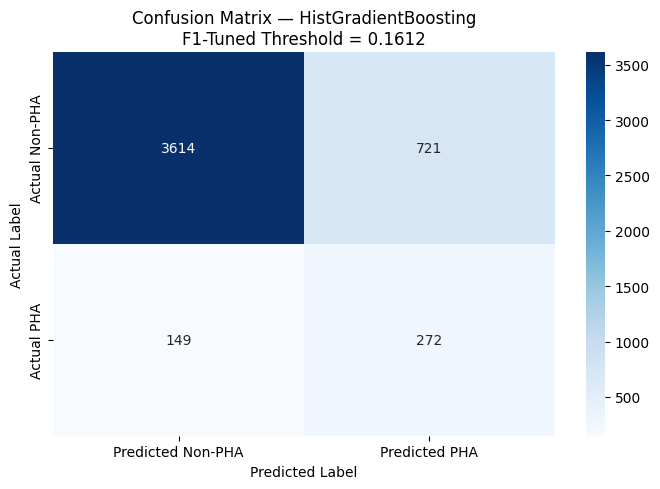

Threshold used: 0.1612
True Negatives: 3614
False Positives: 721
False Negatives: 149
True Positives: 272

Classification Report:
              precision    recall  f1-score   support

     Non-PHA       0.96      0.83      0.89      4335
         PHA       0.27      0.65      0.38       421

    accuracy                           0.82      4756
   macro avg       0.62      0.74      0.64      4756
weighted avg       0.90      0.82      0.85      4756



In [49]:
# Use the threshold selected from training-only out-of-fold predictions
chosen_threshold = float(f1_threshold)

f1_tuned_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

cm_f1 = confusion_matrix(
    y_test,
    f1_tuned_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_f1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Non-PHA", "Predicted PHA"],
    yticklabels=["Actual Non-PHA", "Actual PHA"]
)

plt.title(
    f"Confusion Matrix — {best_model_name}\n"
    f"F1-Tuned Threshold = {chosen_threshold:.4f}"
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_f1.ravel()

print("Threshold used:", round(chosen_threshold, 4))
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        f1_tuned_predictions,
        target_names=["Non-PHA", "PHA"],
        zero_division=0
    )
)


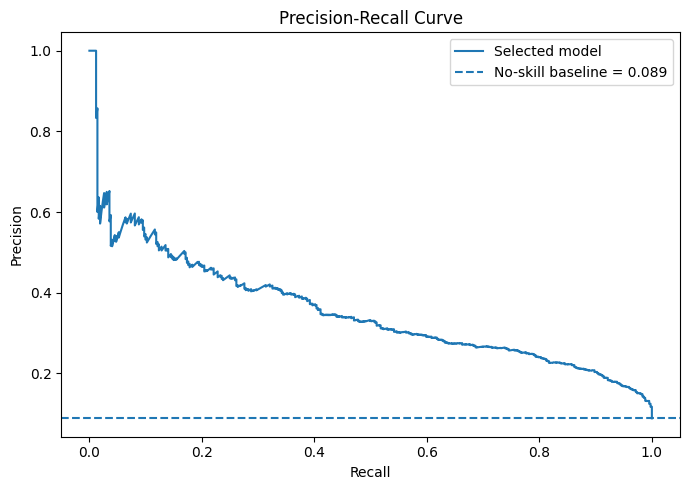

In [50]:
# Precision-recall curve
pr_precision, pr_recall, _ = precision_recall_curve(
    y_test, test_probabilities
)

baseline = y_test.mean()

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label="Selected model")
plt.axhline(
    baseline, linestyle="--",
    label=f"No-skill baseline = {baseline:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()



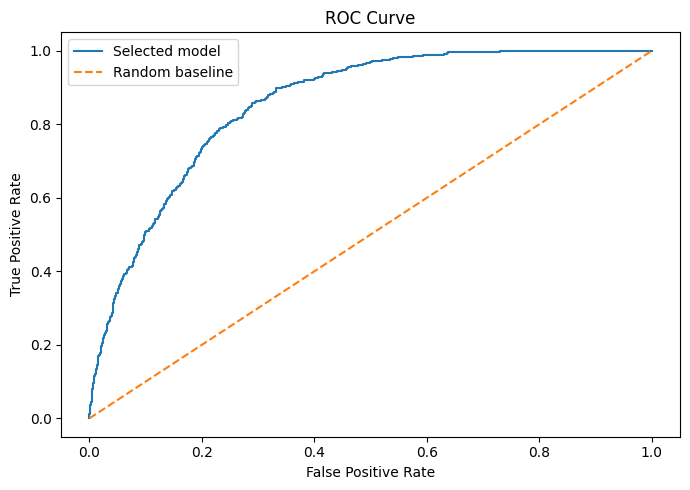

Test PR-AUC: 0.3546
Test ROC-AUC: 0.855
Test positive prevalence: 0.0885


In [51]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Selected model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

print("Test PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
print("Test positive prevalence:", round(float(baseline), 4))

,Feature,Importance_Mean,Importance_Std
2,q,0.2408,0.0047
3,i,0.1345,0.0039
7,w_cos,0.0899,0.0106
1,e,0.0791,0.0099
6,w_sin,0.0669,0.0054
0,a,0.0116,0.0032
4,om_sin,0.0086,0.0035
5,om_cos,0.0026,0.0052
8,ad,0.0015,0.0035
9,n,0.0008,0.0005


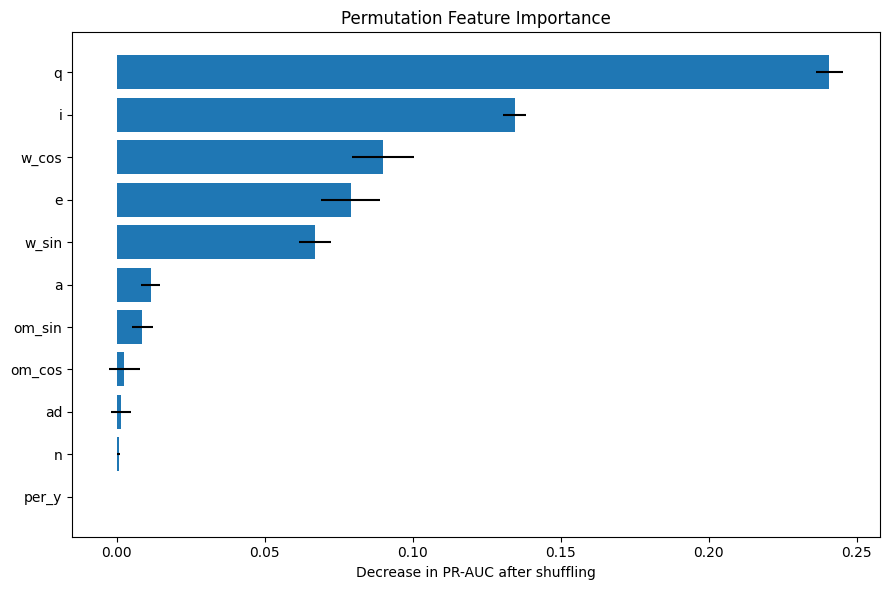

In [52]:
perm = permutation_importance(
    best_model,
    X_test_best,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": best_features,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 6))
plot_imp = importance_df.sort_values("Importance_Mean")
plt.barh(
    plot_imp["Feature"],
    plot_imp["Importance_Mean"],
    xerr=plot_imp["Importance_Std"]
)
plt.xlabel("Decrease in PR-AUC after shuffling")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [53]:
scaling_pipelines = {
    "StandardScaler": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "RobustScaler": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

scaling_results = []

for scaler_name, pipeline in scaling_pipelines.items():
    scores = cross_val_score(
        pipeline,
        X_all.loc[train_idx, best_features],
        y_train,
        scoring="average_precision",
        cv=cv,
        n_jobs=1
    )

    scaling_results.append({
        "Scaling_Method": scaler_name,
        "Mean_CV_PR_AUC": scores.mean(),
        "Std_CV_PR_AUC": scores.std()
    })

scaling_df = pd.DataFrame(scaling_results).sort_values(
    "Mean_CV_PR_AUC", ascending=False
)

display(scaling_df.round(4))

,Scaling_Method,Mean_CV_PR_AUC,Std_CV_PR_AUC
1,RobustScaler,0.1762,0.0062
0,StandardScaler,0.1762,0.0060


In [54]:
outlier_features = [
    c for c in ["a", "e", "q", "i", "ad", "n", "per_y"]
    if c in labelled.columns
]

outlier_rows = []

for col in outlier_features:
    values = labelled[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((values < lower) | (values > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Potential_Outliers": int(count),
        "Outlier_Percentage": 100 * count / len(values)
    })

outlier_df = pd.DataFrame(outlier_rows)
display(outlier_df.round(3))

print(
    "IQR flags unusual values; it does not establish that those values are errors."
)

,Feature,Lower_Bound,Upper_Bound,Potential_Outliers,Outlier_Percentage
0,a,-0.018,3.526,47,0.198
1,e,-0.069,0.952,17,0.071
2,q,0.358,1.496,570,2.397
3,i,-15.047,37.263,856,3.600
4,ad,-0.827,5.933,63,0.265
5,n,-0.228,1.187,780,3.280
6,per_y,-1.132,5.890,115,0.484


IQR flags unusual values; it does not establish that those values are errors.


In [55]:
rng = np.random.default_rng(42)

y_test_array = np.asarray(y_test)
prob_array = np.asarray(test_probabilities)

bootstrap_scores = []
n_test = len(y_test_array)

for _ in range(500):
    sample_idx = rng.integers(0, n_test, size=n_test)
    y_sample = y_test_array[sample_idx]
    p_sample = prob_array[sample_idx]

    # PR-AUC is not informative if a resample contains only one class
    if len(np.unique(y_sample)) < 2:
        continue

    bootstrap_scores.append(
        average_precision_score(y_sample, p_sample)
    )

ci_lower, ci_upper = np.percentile(bootstrap_scores, [2.5, 97.5])
test_pr_auc = average_precision_score(y_test, test_probabilities)

print(f"Test PR-AUC: {test_pr_auc:.4f}")
print(f"Bootstrap 95% interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print("Valid bootstrap samples:", len(bootstrap_scores))

Test PR-AUC: 0.3546
Bootstrap 95% interval: [0.3127, 0.4010]
Valid bootstrap samples: 500


In [56]:
import os
import json
import zipfile
from google.colab import files

output_dir = "pha_project_outputs"
figure_dir = os.path.join(output_dir, "figures")

os.makedirs(figure_dir, exist_ok=True)

# Save result tables
missing_audit.to_csv(
    os.path.join(output_dir, "missing_value_audit.csv")
)
cv_results_df.to_csv(
    os.path.join(output_dir, "cross_validation_results.csv"),
    index=False
)
test_results_df.to_csv(
    os.path.join(output_dir, "test_set_model_comparison.csv"),
    index=False
)
diagnostic_df.to_csv(
    os.path.join(output_dir, "leakage_proxy_diagnostics.csv"),
    index=False
)
threshold_results_df.to_csv(
    os.path.join(output_dir, "threshold_comparison.csv"),
    index=False
)
importance_df.to_csv(
    os.path.join(output_dir, "permutation_feature_importance.csv"),
    index=False
)
scaling_df.to_csv(
    os.path.join(output_dir, "scaling_comparison.csv"),
    index=False
)
outlier_df.to_csv(
    os.path.join(output_dir, "outlier_audit.csv"),
    index=False
)

# Save the labelled dataset after target cleaning and feature engineering
labelled.to_csv(
    os.path.join(output_dir, "cleaned_labelled_asteroids.csv"),
    index=False
)

# Save key run details for reproducibility
metadata = {
    "random_state": 42,
    "test_size": 0.20,
    "cross_validation_folds": 3,
    "selected_model": best_model_name,
    "selected_feature_set": best_feature_name,
    "selected_features": best_features,
    "test_pr_auc": float(test_pr_auc),
    "test_roc_auc": float(roc_auc_score(y_test, test_probabilities)),
    "bootstrap_95_percent_interval": [
        float(ci_lower), float(ci_upper)
    ]
}

with open(os.path.join(output_dir, "run_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# Save plots from the currently active notebook figures, if any.
# For reliable paper-quality files, save each plot directly with
# plt.savefig(...) before plt.show() in its respective cell.

zip_name = "pha_project_outputs.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(output_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zipf.write(
                full_path,
                arcname=os.path.relpath(full_path, ".")
            )

print("Results saved in:", output_dir)
print("ZIP created:", zip_name)

files.download(zip_name)

Results saved in: pha_project_outputs
ZIP created: pha_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

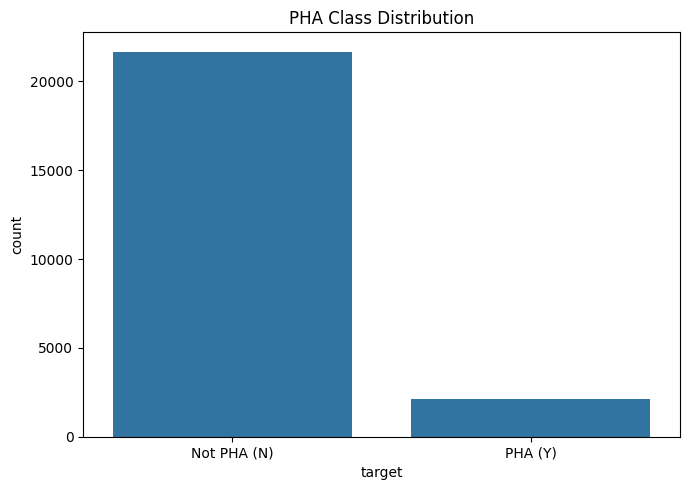

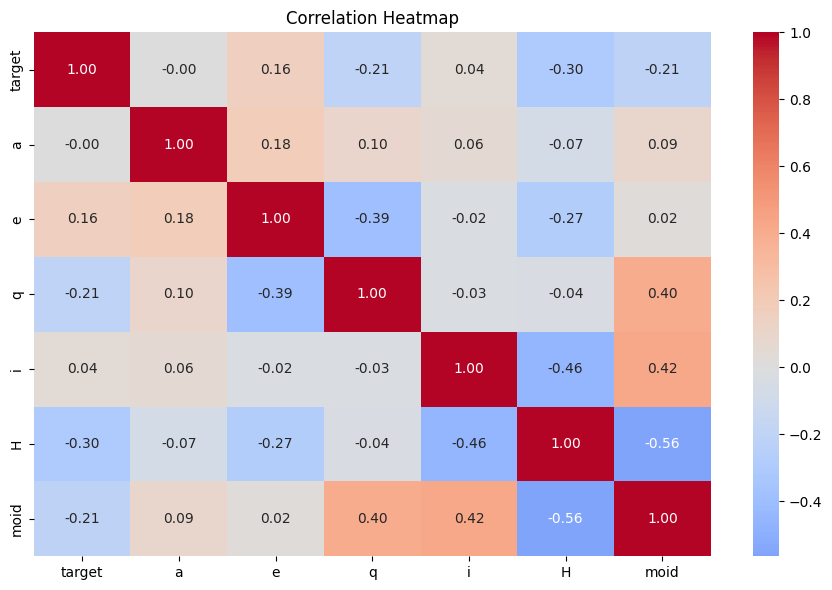

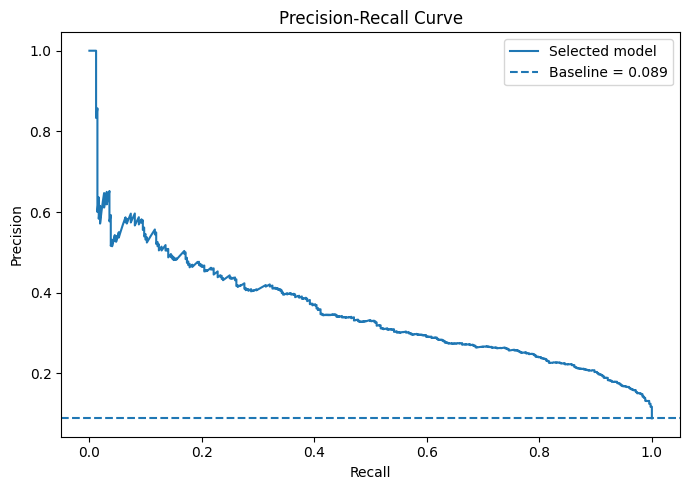

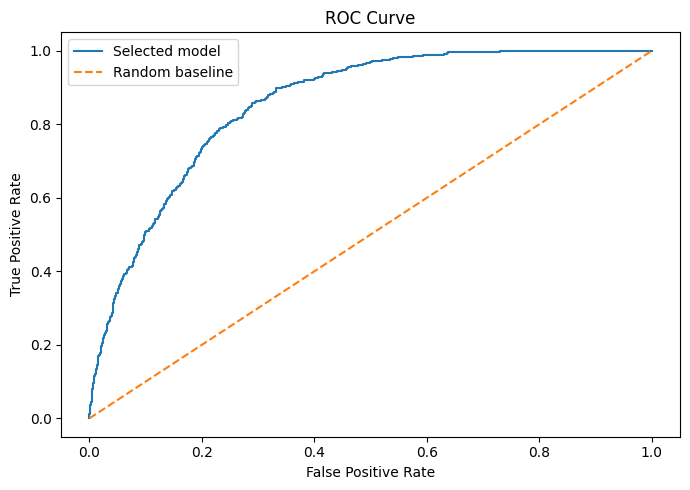

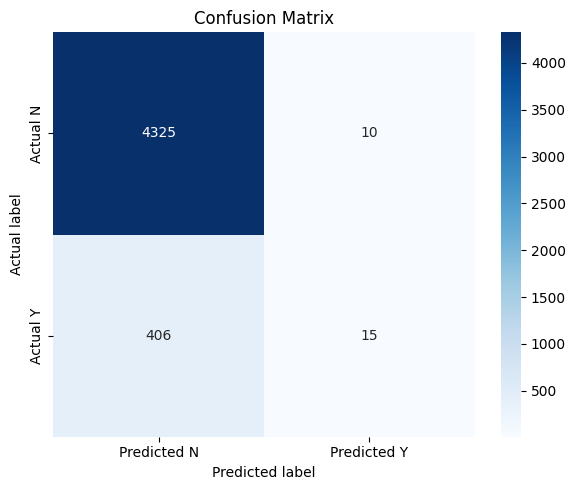

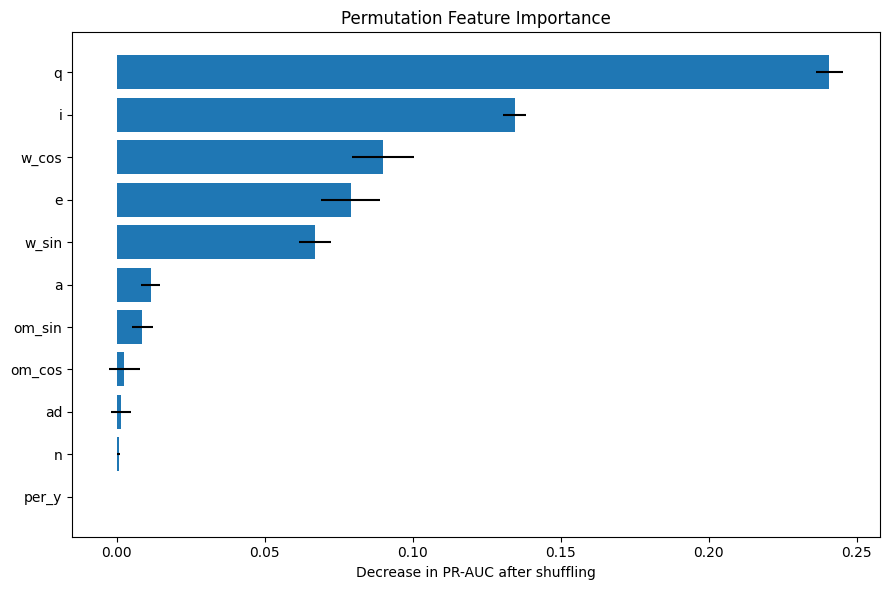

All six main figures saved at 300 DPI.


In [57]:
# Save the figures needed for your report/paper
plt.figure(figsize=(7, 5))
sns.countplot(data=labelled, x="target")
plt.xticks([0, 1], ["Not PHA (N)", "PHA (Y)"])
plt.title("PHA Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "01_class_distribution.png"), dpi=300)
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    labelled[["target", "a", "e", "q", "i", "H", "moid"]]
    .corr(numeric_only=True),
    annot=True, cmap="coolwarm", center=0, fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "02_correlation_heatmap.png"), dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label="Selected model")
plt.axhline(baseline, linestyle="--", label=f"Baseline = {baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "03_precision_recall_curve.png"), dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Selected model")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "04_roc_curve.png"), dpi=300)
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted N", "Predicted Y"],
    yticklabels=["Actual N", "Actual Y"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "05_confusion_matrix.png"), dpi=300)
plt.show()

plt.figure(figsize=(9, 6))
plot_imp = importance_df.sort_values("Importance_Mean")
plt.barh(
    plot_imp["Feature"],
    plot_imp["Importance_Mean"],
    xerr=plot_imp["Importance_Std"]
)
plt.xlabel("Decrease in PR-AUC after shuffling")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "06_feature_importance.png"), dpi=300)
plt.show()

print("All six main figures saved at 300 DPI.")

In [58]:
import zipfile
import os
from google.colab import files

zip_name = "pha_project_outputs.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(output_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zipf.write(
                full_path,
                arcname=os.path.relpath(full_path, ".")
            )

print("Export complete!")
print("Results folder:", output_dir)
print("ZIP file:", zip_name)

files.download(zip_name)

Export complete!
Results folder: pha_project_outputs
ZIP file: pha_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>